 BUNDLED THREE-PHASE TRANSMISSION LINE CALCULATOR

AVAILABLE CONDUCTORS
1. Solid round (GMR factor = 0.7788)
2. Stranded, 7 strands (GMR factor = 0.726)
3. Stranded, 19 strands (GMR factor = 0.758)
4. Stranded, 37 strands (GMR factor = 0.768)
5. ACSR 26/7 (GMR factor = 0.81)


Select conductor type (1-5):  1
Enter physical radius of one sub-conductor (m):  0.05

Enter sub-conductors per bundle (2, 3 or 4):  3
Enter distance between adjacent sub-conductors (m):  0.3
Enter distance between phase 1 and phase 2 (m):  2.8
Enter distance between phase 2 and phase 3 (m):  2.8



       TRANSMISSION LINE CALCULATION RESULTS
                   Parameter        Value
              Conductor type  Solid round
   Sub-conductors per bundle            3
    Sub-conductor radius (m)     0.050000
    Single conductor GMR (m)     0.038940
 Geometric mean distance (m)     3.527779
              Bundle GMR (m)     0.151896
Bundle equivalent radius (m)     0.165096
  Inductance per phase (H/m) 6.290456e-07
 Capacitance per phase (F/m) 1.816892e-11

COMPARISON WITH ONE CONDUCTOR PER PHASE
Unbundled inductance  = 9.012804e-07 H/m
Bundled inductance    = 6.290456e-07 H/m
Unbundled capacitance = 1.307004e-11 F/m
Bundled capacitance   = 1.816892e-11 F/m
Inductance reduction = 30.21%
Capacitance increase = 39.01%


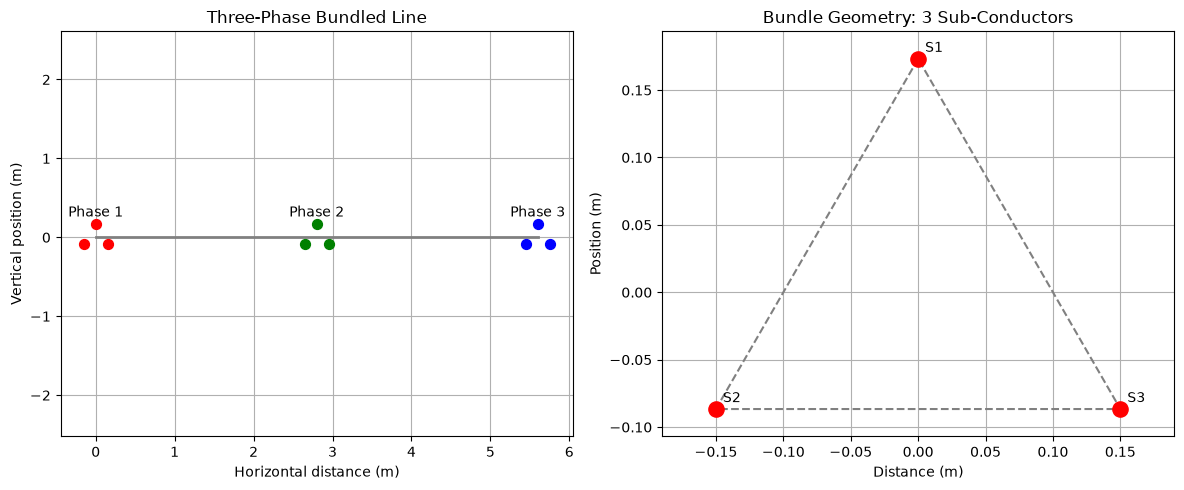

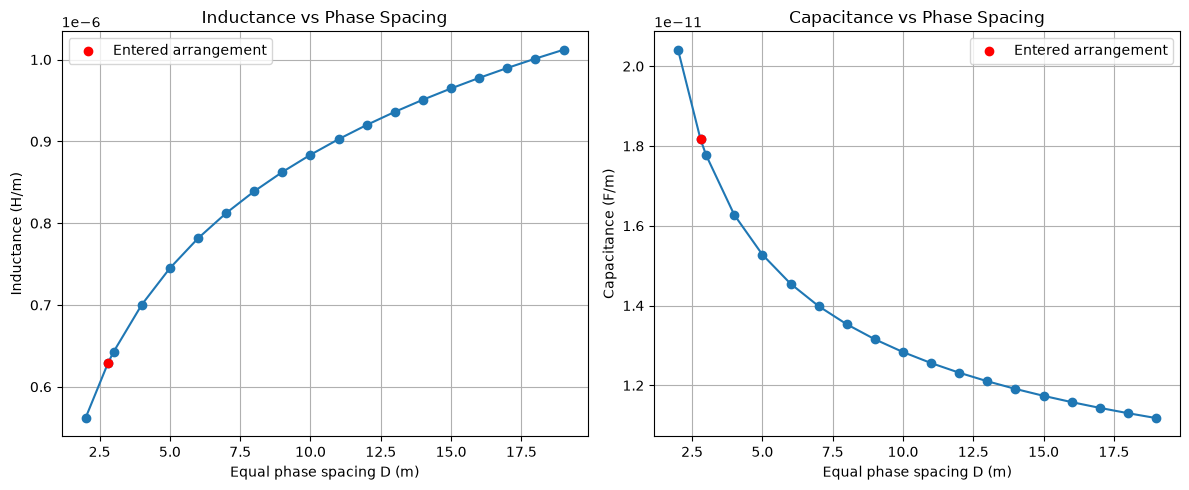

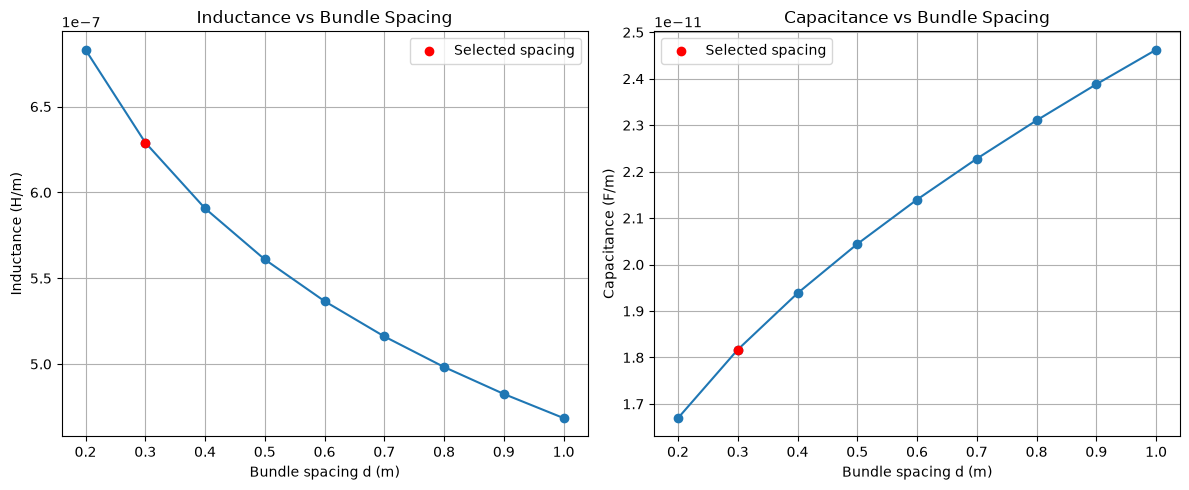


EFFECT OF NUMBER OF SUB-CONDUCTORS
 Sub-conductors Bundle GMR (m) Equivalent radius (m) Inductance (H/m) Capacitance (F/m)
              2       0.108083              0.122474     6.971043e-07      1.655437e-11
              3       0.151896              0.165096     6.290456e-07      1.816892e-11
              4       0.196367              0.209032     5.776876e-07      1.968597e-11


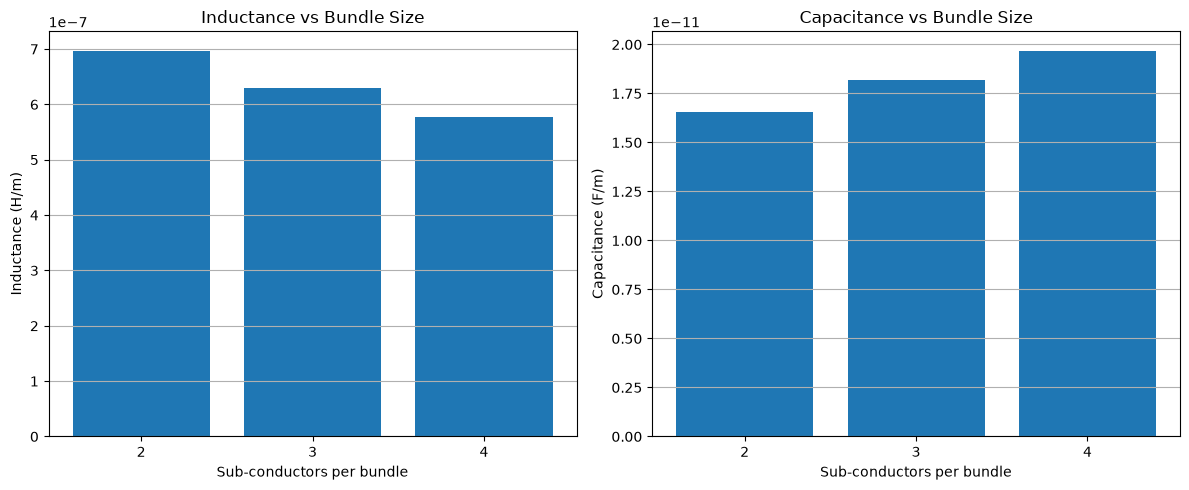


CONCLUSION
1. Increasing phase spacing increases inductance.
2. Increasing phase spacing decreases capacitance.
3. Bundling generally reduces inductance.
4. Bundling generally increases capacitance.
5. Increasing bundle spacing generally reduces inductance
   and increases capacitance.

Program completed.


In [1]:
# ============================================================
# THREE-PHASE TRANSMISSION LINE WITH BUNDLED CONDUCTORS
# Calculation of GMR, GMD, Inductance and Capacitance
# ============================================================

import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

EPSILON_0 = 8.854e-12

CONDUCTORS = {
    "1": ("Solid round", 0.7788),
    "2": ("Stranded, 7 strands", 0.726),
    "3": ("Stranded, 19 strands", 0.758),
    "4": ("Stranded, 37 strands", 0.768),
    "5": ("ACSR 26/7", 0.81)
}


# ============================================================
# STEP 1: GET VALID INPUTS
# ============================================================

def positive_input(message):
    while True:
        try:
            value = float(input(message))
            if math.isfinite(value) and value > 0:
                return value
            print("Enter a positive number.")
        except ValueError:
            print("Invalid input. Enter a number.")


def select_conductor():
    print("\nAVAILABLE CONDUCTORS")
    for key, (name, factor) in CONDUCTORS.items():
        print(f"{key}. {name} (GMR factor = {factor})")

    while True:
        choice = input("Select conductor type (1-5): ").strip()
        if choice in CONDUCTORS:
            return CONDUCTORS[choice]
        print("Invalid selection. Choose 1, 2, 3, 4 or 5.")


def select_bundle():
    while True:
        try:
            n = int(input(
                "\nEnter sub-conductors per bundle (2, 3 or 4): "
            ))
            if n in (2, 3, 4):
                return n
        except ValueError:
            pass
        print("Only 2, 3 or 4 is allowed.")


# ============================================================
# STEP 2: BUNDLE GEOMETRY AND EQUIVALENT RADII
# ============================================================

def bundle_positions(n, spacing):
    start_angles = {2: 0, 3: 90, 4: 45}

    radius = spacing / (2 * math.sin(math.pi / n))

    angles = (
        math.radians(start_angles[n])
        + 2 * math.pi * np.arange(n) / n
    )

    x = radius * np.cos(angles)
    y = radius * np.sin(angles)

    return x, y


def bundle_parameters(n, spacing, gmr, conductor_radius):
    x, y = bundle_positions(n, spacing)

    product_gmr = gmr
    product_radius = conductor_radius

    for j in range(1, n):
        distance = math.hypot(
            x[0] - x[j],
            y[0] - y[j]
        )

        product_gmr *= distance
        product_radius *= distance

    bundle_gmr = product_gmr ** (1 / n)
    bundle_radius = product_radius ** (1 / n)

    return bundle_gmr, bundle_radius


# ============================================================
# STEP 3: GMD, INDUCTANCE AND CAPACITANCE
# ============================================================

def calculate_gmd(d12, d23):
    d13 = d12 + d23
    return (d12 * d23 * d13) ** (1 / 3)


def calculate_parameters(gmd, gmr, radius):
    if gmd <= gmr or gmd <= radius:
        raise ValueError(
            "GMD must be greater than both equivalent radii. "
            "Check your phase spacing and bundle dimensions."
        )

    inductance = 2e-7 * math.log(gmd / gmr)

    capacitance = (
        2 * math.pi * EPSILON_0
        / math.log(gmd / radius)
    )

    return inductance, capacitance


# ============================================================
# STEP 4: DISPLAY CALCULATED RESULTS
# ============================================================

def display_results(name, n, r, gmr, gmd,
                    bundle_gmr, bundle_radius,
                    inductance, capacitance,
                    single_l, single_c):

    results = pd.DataFrame({
        "Parameter": [
            "Conductor type",
            "Sub-conductors per bundle",
            "Sub-conductor radius (m)",
            "Single conductor GMR (m)",
            "Geometric mean distance (m)",
            "Bundle GMR (m)",
            "Bundle equivalent radius (m)",
            "Inductance per phase (H/m)",
            "Capacitance per phase (F/m)"
        ],
        "Value": [
            name, n,
            f"{r:.6f}",
            f"{gmr:.6f}",
            f"{gmd:.6f}",
            f"{bundle_gmr:.6f}",
            f"{bundle_radius:.6f}",
            f"{inductance:.6e}",
            f"{capacitance:.6e}"
        ]
    })

    print("\n" + "=" * 60)
    print("       TRANSMISSION LINE CALCULATION RESULTS")
    print("=" * 60)
    print(results.to_string(index=False))

    print("\nCOMPARISON WITH ONE CONDUCTOR PER PHASE")
    print(f"Unbundled inductance  = {single_l:.6e} H/m")
    print(f"Bundled inductance    = {inductance:.6e} H/m")
    print(f"Unbundled capacitance = {single_c:.6e} F/m")
    print(f"Bundled capacitance   = {capacitance:.6e} F/m")

    print(
        "Inductance reduction = "
        f"{(1 - inductance / single_l) * 100:.2f}%"
    )
    print(
        "Capacitance increase = "
        f"{(capacitance / single_c - 1) * 100:.2f}%"
    )


# ============================================================
# STEP 5: DRAW THE THREE-PHASE CONDUCTOR ARRANGEMENT
# ============================================================

def plot_arrangement(n, spacing, d12, d23):
    bx, by = bundle_positions(n, spacing)

    phase_x = [0, d12, d12 + d23]
    colours = ["red", "green", "blue"]
    labels = ["Phase 1", "Phase 2", "Phase 3"]

    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    # Complete arrangement
    ax[0].plot(
        [0, d12 + d23], [0, 0],
        color="gray", linewidth=2
    )

    for x0, colour, label in zip(phase_x, colours, labels):
        ax[0].scatter(
            x0 + bx, by,
            color=colour, s=50, zorder=3
        )
        ax[0].annotate(
            label, (x0, 0),
            xytext=(0, 15),
            textcoords="offset points",
            ha="center"
        )

    ax[0].set_title("Three-Phase Bundled Line")
    ax[0].set_xlabel("Horizontal distance (m)")
    ax[0].set_ylabel("Vertical position (m)")
    ax[0].grid(True)
    ax[0].set_aspect("equal", adjustable="datalim")

    # Zoomed bundle
    ax[1].plot(
        np.append(bx, bx[0]),
        np.append(by, by[0]),
        "--", color="gray"
    )
    ax[1].scatter(bx, by, color="red", s=120, zorder=3)

    for i, (x, y) in enumerate(zip(bx, by), start=1):
        ax[1].annotate(
            f"S{i}", (x, y),
            xytext=(5, 5),
            textcoords="offset points"
        )

    ax[1].set_title(f"Bundle Geometry: {n} Sub-Conductors")
    ax[1].set_xlabel("Distance (m)")
    ax[1].set_ylabel("Position (m)")
    ax[1].grid(True)
    ax[1].set_aspect("equal", adjustable="datalim")

    plt.tight_layout()
    plt.show()


# ============================================================
# STEP 6: EFFECT OF PHASE SPACING
# ============================================================

def plot_phase_effect(gmd, bundle_gmr, bundle_radius, L, C):
    # For equal spacing, GMD = 2^(1/3) * D
    d_equivalent = gmd / (2 ** (1 / 3))

    spacings = np.unique(np.round(
        np.append(np.arange(2, 20), d_equivalent), 6
    ))

    inductances = []
    capacitances = []

    for D in spacings:
        gmd_test = (D * D * 2 * D) ** (1 / 3)

        li, ci = calculate_parameters(
            gmd_test, bundle_gmr, bundle_radius
        )

        inductances.append(li)
        capacitances.append(ci)

    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    ax[0].plot(spacings, inductances, "o-")
    ax[0].scatter(
        [d_equivalent], [L],
        color="red", label="Entered arrangement", zorder=3
    )
    ax[0].set_title("Inductance vs Phase Spacing")
    ax[0].set_xlabel("Equal phase spacing D (m)")
    ax[0].set_ylabel("Inductance (H/m)")
    ax[0].legend()
    ax[0].grid(True)

    ax[1].plot(spacings, capacitances, "o-")
    ax[1].scatter(
        [d_equivalent], [C],
        color="red", label="Entered arrangement", zorder=3
    )
    ax[1].set_title("Capacitance vs Phase Spacing")
    ax[1].set_xlabel("Equal phase spacing D (m)")
    ax[1].set_ylabel("Capacitance (F/m)")
    ax[1].legend()
    ax[1].grid(True)

    plt.tight_layout()
    plt.show()


# ============================================================
# STEP 7: EFFECT OF BUNDLE SPACING
# ============================================================

def plot_bundle_effect(n, spacing, gmr, radius, gmd):
    spacings = np.unique(np.round(
        np.append(np.linspace(0.2, 1.0, 9), spacing), 6
    ))

    inductances = []
    capacitances = []

    for d in spacings:
        bg, br = bundle_parameters(n, d, gmr, radius)

        li, ci = calculate_parameters(gmd, bg, br)

        inductances.append(li)
        capacitances.append(ci)

    actual_gmr, actual_radius = bundle_parameters(
        n, spacing, gmr, radius
    )
    actual_l, actual_c = calculate_parameters(
        gmd, actual_gmr, actual_radius
    )

    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    ax[0].plot(spacings, inductances, "o-")
    ax[0].scatter(
        [spacing], [actual_l],
        color="red", label="Selected spacing", zorder=3
    )
    ax[0].set_title("Inductance vs Bundle Spacing")
    ax[0].set_xlabel("Bundle spacing d (m)")
    ax[0].set_ylabel("Inductance (H/m)")
    ax[0].legend()
    ax[0].grid(True)

    ax[1].plot(spacings, capacitances, "o-")
    ax[1].scatter(
        [spacing], [actual_c],
        color="red", label="Selected spacing", zorder=3
    )
    ax[1].set_title("Capacitance vs Bundle Spacing")
    ax[1].set_xlabel("Bundle spacing d (m)")
    ax[1].set_ylabel("Capacitance (F/m)")
    ax[1].legend()
    ax[1].grid(True)

    plt.tight_layout()
    plt.show()


# ============================================================
# STEP 8: EFFECT OF NUMBER OF SUB-CONDUCTORS
# ============================================================

def compare_bundle_sizes(spacing, gmr, radius, gmd):
    counts = [2, 3, 4]
    rows = []
    inductances = []
    capacitances = []

    for n in counts:
        bg, br = bundle_parameters(n, spacing, gmr, radius)
        li, ci = calculate_parameters(gmd, bg, br)

        rows.append([
            n, f"{bg:.6f}", f"{br:.6f}",
            f"{li:.6e}", f"{ci:.6e}"
        ])

        inductances.append(li)
        capacitances.append(ci)

    table = pd.DataFrame(rows, columns=[
        "Sub-conductors",
        "Bundle GMR (m)",
        "Equivalent radius (m)",
        "Inductance (H/m)",
        "Capacitance (F/m)"
    ])

    print("\nEFFECT OF NUMBER OF SUB-CONDUCTORS")
    print(table.to_string(index=False))

    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    ax[0].bar([str(n) for n in counts], inductances)
    ax[0].set_title("Inductance vs Bundle Size")
    ax[0].set_xlabel("Sub-conductors per bundle")
    ax[0].set_ylabel("Inductance (H/m)")
    ax[0].grid(True, axis="y")

    ax[1].bar([str(n) for n in counts], capacitances)
    ax[1].set_title("Capacitance vs Bundle Size")
    ax[1].set_xlabel("Sub-conductors per bundle")
    ax[1].set_ylabel("Capacitance (F/m)")
    ax[1].grid(True, axis="y")

    plt.tight_layout()
    plt.show()


# ============================================================
# STEP 9: MAIN PROGRAM
# ============================================================

def main():
    print("=" * 60)
    print(" BUNDLED THREE-PHASE TRANSMISSION LINE CALCULATOR")
    print("=" * 60)

    name, factor = select_conductor()

    radius = positive_input(
        "Enter physical radius of one sub-conductor (m): "
    )
    gmr = factor * radius

    n = select_bundle()

    spacing = positive_input(
        "Enter distance between adjacent sub-conductors (m): "
    )

    d12 = positive_input(
        "Enter distance between phase 1 and phase 2 (m): "
    )
    d23 = positive_input(
        "Enter distance between phase 2 and phase 3 (m): "
    )

    gmd = calculate_gmd(d12, d23)

    bundle_gmr, bundle_radius = bundle_parameters(
        n, spacing, gmr, radius
    )

    inductance, capacitance = calculate_parameters(
        gmd, bundle_gmr, bundle_radius
    )

    single_l, single_c = calculate_parameters(
        gmd, gmr, radius
    )

    display_results(
        name, n, radius, gmr, gmd,
        bundle_gmr, bundle_radius,
        inductance, capacitance, single_l, single_c
    )

    plot_arrangement(n, spacing, d12, d23)

    plot_phase_effect(
        gmd, bundle_gmr, bundle_radius,
        inductance, capacitance
    )

    plot_bundle_effect(
        n, spacing, gmr, radius, gmd
    )

    compare_bundle_sizes(spacing, gmr, radius, gmd)

    print("\nCONCLUSION")
    print("1. Increasing phase spacing increases inductance.")
    print("2. Increasing phase spacing decreases capacitance.")
    print("3. Bundling generally reduces inductance.")
    print("4. Bundling generally increases capacitance.")
    print("5. Increasing bundle spacing generally reduces inductance")
    print("   and increases capacitance.")
    print("\nProgram completed.")


if __name__ == "__main__":
    try:
        main()
    except ValueError as error:
        print("\nINPUT OR CALCULATION ERROR:", error)